# NUTDTS 816 · Case Study 1: Forecasting Nigerian inflation for budget planning (5%)


**Name / Group:** Fregene Ofe Favour, Philip Adeiza Oricha ---  **Date:** 19/10/2026

This notebook must run top to bottom from a fresh Colab runtime. Keep the section headings; put your commentary in the markdown cells and your code in the code cells. Finish with the AI-use statement.

In [1]:
# ---- Setup: run once per Colab session ----
# 1. Install the course libraries
!pip install -q statsmodels pmdarima statsforecast neuralforecast lightgbm arch plotly

# 2. Fetch the course data module and data snapshots from the course repository.
REPO = "https://raw.githubusercontent.com/toadesina/NUTDTS816_Course_Repository/main"
import urllib.request, os
os.makedirs("data", exist_ok=True)
urllib.request.urlretrieve(f"{REPO}/src/tsdata.py", "tsdata.py")
DATA_FILES = ["nigeria_cpi", "bonny_light", "nigeria_fx"]
for f in DATA_FILES:
    urllib.request.urlretrieve(f"{REPO}/data/{f}.csv", f"data/{f}.csv")

import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
import tsdata
print("Setup complete.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.3/331.3 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 MB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.4/50.4 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
pd.set_option("display.width", 140)
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson
import tsdata
GOLD, BLUE, GREY, RED = "#B8860B", "#2F6DB5", "#555555", "#B03A2E"
SEED = 816
print("Setup complete.")

Setup complete.


Exploratory Data Analysis

In [3]:
#1. Load and tidy both series into pandas with a proper DatetimeIndex at the correct frequency.
# Fetch the Cpi data
cpi = tsdata.nigeria_cpi()
print(type(cpi), cpi.index.freq)
print(cpi.head(6))
print(cpi.index[:3])

print()
print('-' * 40)
print()

#Fetch the Bonny light data
bonny = tsdata.bonny_light()
print(type(bonny), bonny.index.freq)
print(bonny.head(6))
print(bonny.index[:3])

print()
print('-' * 40)
print()

#Fetch the FX data
fx = tsdata.nigeria_fx()
print(type(fx), fx.index.freq)
print(fx.head(6))
print(fx.index[:3])

<class 'pandas.core.series.Series'> <MonthBegin>
date
2014-01-01    20.1179
2014-02-01    20.2179
2014-03-01    20.3766
2014-04-01    20.5019
2014-05-01    20.6615
2014-06-01    20.8214
Freq: MS, Name: cpi, dtype: float64
DatetimeIndex(['2014-01-01', '2014-02-01', '2014-03-01'], dtype='datetime64[ns]', name='date', freq='MS')

----------------------------------------

<class 'pandas.core.series.Series'> <MonthBegin>
date
2015-01-01    48.81
2015-02-01    58.09
2015-03-01    56.69
2015-04-01    57.45
2015-05-01    65.08
2015-06-01    62.06
Freq: MS, Name: bonny_light, dtype: float64
DatetimeIndex(['2015-01-01', '2015-02-01', '2015-03-01'], dtype='datetime64[ns]', name='date', freq='MS')

----------------------------------------

<class 'pandas.core.series.Series'> <MonthBegin>
date
2015-01-01    167.5000
2015-02-01    178.1500
2015-03-01    196.5727
2015-04-01    196.5000
2015-05-01    196.5000
2015-06-01    196.4159
Freq: MS, Name: ngn_usd, dtype: float64
DatetimeIndex(['2015-01-01', '

In [4]:
#Check for missing values for both data
cpi_isnull = cpi.isnull().sum()
print("Total CPI missing value:", cpi_isnull)

bonny_isnull = bonny.isnull().sum()
print("Total Bonny_Light missing value:", bonny_isnull)

fx_isnull = fx.isnull().sum()
print("Total FX missing value:", fx_isnull)

Total CPI missing value: 0
Total Bonny_Light missing value: 0
Total FX missing value: 0


In [5]:
#Check for duplicates
cpi_duplicate = cpi.index.duplicated().sum()
print("Total CPI Duplicate:", cpi_duplicate)

bonny_duplicate = bonny.index.duplicated().sum()
print("Total Bonny_Light Duplicate:", bonny_duplicate)

fx_duplicate = fx.index.duplicated().sum()
print("Total FX Duplicate:", fx_duplicate)

Total CPI Duplicate: 0
Total Bonny_Light Duplicate: 0
Total FX Duplicate: 0


## 1. Structure of the inflation series

*monthly log changes; decomposition; events named from the Context Note*

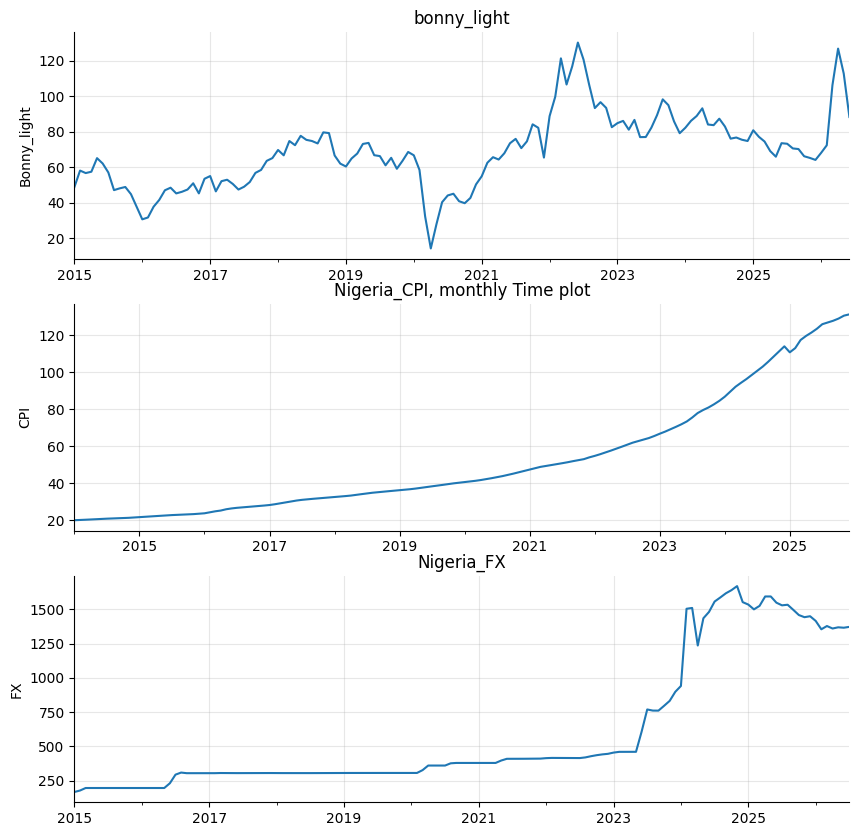

In [6]:
#Time plot
fig, axes = plt.subplots(3,1, figsize=(10, 10))
bonny.plot(ax=axes[0], title='bonny_light', ylabel= 'Bonny_light', xlabel= 'Year')
cpi.plot(ax=axes[1], title='Nigeria_CPI, monthly Time plot', ylabel='CPI', xlabel='Year')
fx.plot(ax=axes[2], title='Nigeria_FX', ylabel='FX', xlabel='Year')
for ax in axes.flat: ax.set_xlabel('')

In [7]:
#month-on-month inflation, % log change
#year-on-year inflation implied by the index, %

infl = (100 * np.log(cpi).diff()).dropna(); infl.name = "infl"
yoy  = (100 * (cpi / cpi.shift(12) - 1)).dropna()


# NBS rebasing: methodological step, not deflation
SEAM = pd.Timestamp("2025-01-01")

#For methods that cannot take a dummy (benchmarks, STL) the seam month is treated as missing and interpolated;
#The seam month is never scored as a forecast target here.
infl_p = infl.copy(); infl_p[SEAM] = np.nan; infl_p = infl_p.interpolate()

print(f"CPI: {cpi.index[0]:%b %Y} - {cpi.index[-1]:%b %Y} ({len(cpi)} months);  FX to {fx.index[-1]:%b %Y};  bonny to {bonny.index[-1]:%b %Y}")
print(f"Seam check: CPI Dec 2024 = {cpi['2024-12-01']:.2f}, Jan 2025 = {cpi['2025-01-01']:.2f}, m/m = {infl[SEAM]:.2f}%  (methodological)")
print(f"Index-implied YoY: Jan 2025 = {yoy['2025-01-01']:.2f}% (NBS announced 24.5%);  Dec 2025 = {yoy['2025-12-01']:.2f}% (NBS 15.15%)")
print("\nLast 12 months of the snapshot:")
print(pd.DataFrame({"CPI": cpi, "m/m %": infl, "YoY %": yoy}).loc["2025"].round(2).to_string())

CPI: Jan 2014 - Dec 2025 (144 months);  FX to Jul 2026;  bonny to Jun 2026
Seam check: CPI Dec 2024 = 113.91, Jan 2025 = 110.68, m/m = -2.88%  (methodological)
Index-implied YoY: Jan 2025 = 27.61% (NBS announced 24.5%);  Dec 2025 = 15.15% (NBS 15.15%)

Last 12 months of the snapshot:
               CPI  m/m %  YoY %
date                            
2025-01-01  110.68  -2.88  27.61
2025-02-01  112.94   2.02  26.27
2025-03-01  117.34   3.82  27.35
2025-04-01  119.52   1.84  26.82
2025-05-01  121.35   1.52  26.06
2025-06-01  123.39   1.67  25.29
2025-07-01  125.85   1.97  24.94
2025-08-01  126.79   0.74  23.14
2025-09-01  127.70   0.72  20.98
2025-10-01  128.89   0.93  18.97
2025-11-01  130.47   1.22  17.33
2025-12-01  131.17   0.54  15.15


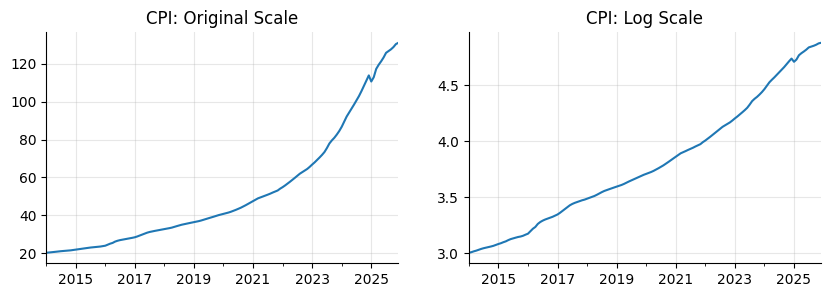

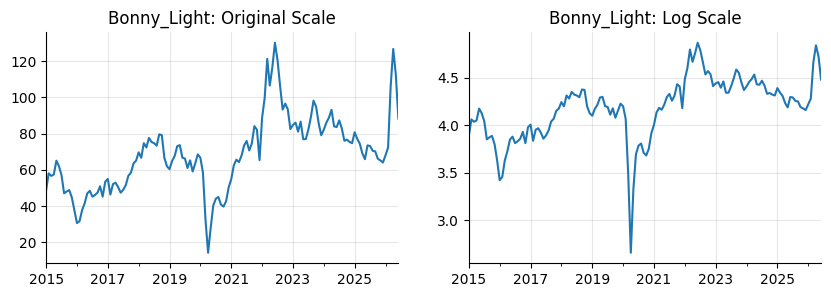

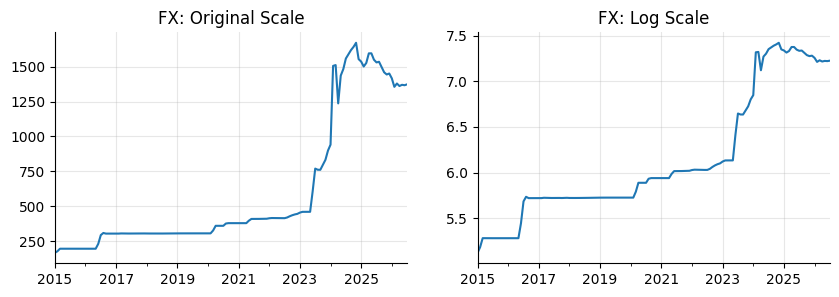

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
cpi.plot(ax=axes[0], title='CPI: Original Scale')
np.log(cpi).plot(ax=axes[1], title='CPI: Log Scale')
for ax in axes: ax.set_xlabel('')

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
bonny.plot(ax=axes[0], title='Bonny_Light: Original Scale')
np.log(bonny).plot(ax=axes[1], title='Bonny_Light: Log Scale')
for ax in axes: ax.set_xlabel('')

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
fx.plot(ax=axes[0], title='FX: Original Scale')
np.log(fx).plot(ax=axes[1], title='FX: Log Scale')
for ax in axes: ax.set_xlabel('')

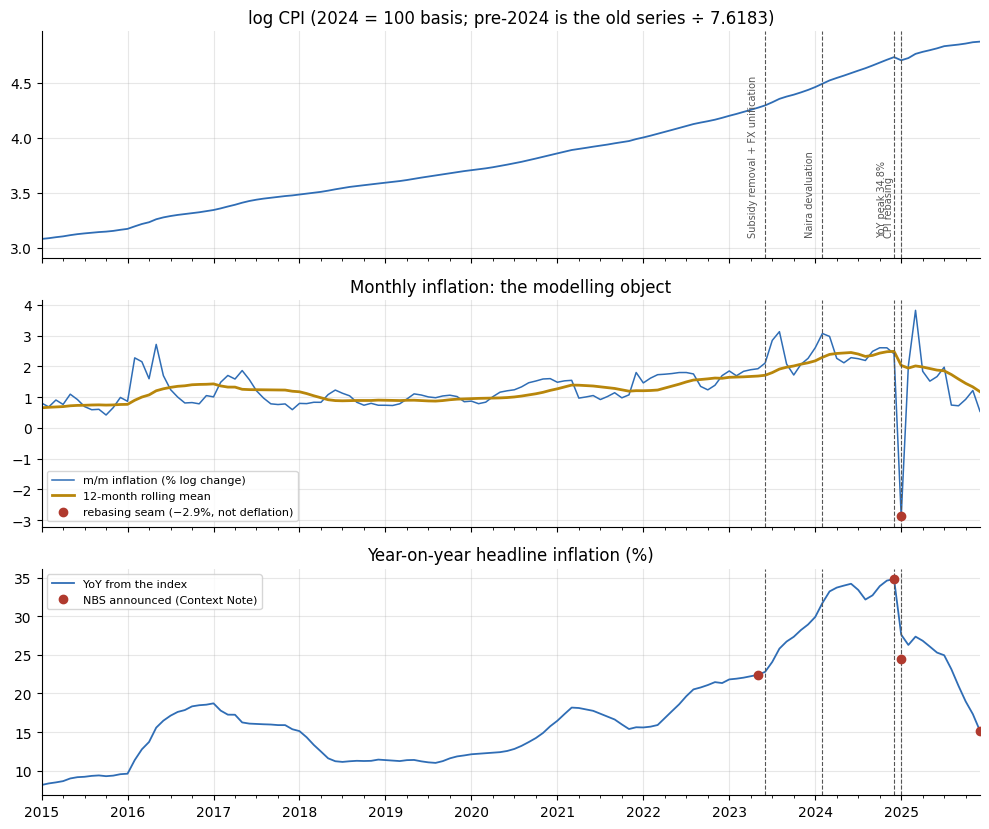

In [9]:
# 1b.The series with the Context-Note events marked
events = {"2023-06-01": "Subsidy removal +\nFX unification", "2024-02-01": "Naira\ndevaluation",
          "2024-12-01": "YoY peak\n34.8%", "2025-01-01": "CPI\nrebasing"}
fig, axes = plt.subplots(3, 1, figsize=(10, 8.4), sharex=True)
np.log(cpi).plot(ax=axes[0], lw=1.3, color=BLUE); axes[0].set_title("log CPI (2024 = 100 basis; pre-2024 is the old series ÷ 7.6183)")
infl.plot(ax=axes[1], lw=1.1, color=BLUE, label="m/m inflation (% log change)")
infl.rolling(12).mean().plot(ax=axes[1], lw=2, color=GOLD, label="12-month rolling mean")
axes[1].scatter([SEAM], [infl[SEAM]], color=RED, zorder=5, label="rebasing seam (−2.9%, not deflation)")
axes[1].set_title("Monthly inflation: the modelling object"); axes[1].legend(fontsize=8, loc="lower left")
yoy.plot(ax=axes[2], lw=1.3, color=BLUE, label="YoY from the index")
nbs = pd.Series({pd.Timestamp("2023-05-01"): 22.4, pd.Timestamp("2024-12-01"): 34.8, pd.Timestamp("2025-01-01"): 24.5, pd.Timestamp("2025-12-01"): 15.15})
axes[2].scatter(nbs.index, nbs.values, color=RED, zorder=5, label="NBS announced (Context Note)")
axes[2].set_title("Year-on-year headline inflation (%)"); axes[2].legend(fontsize=8)
for ax in axes:
    for d, lab in events.items():
        ax.axvline(pd.Timestamp(d), color=GREY, lw=0.8, ls="--")
    ax.set_xlabel("")
for d, lab in events.items():
    axes[0].text(pd.Timestamp(d) - pd.Timedelta(days=12), 3.1, lab.replace("\n", " "), fontsize=7, rotation=90, ha="right", va="bottom", color=GREY)
plt.tight_layout(); plt.show()

In [10]:
# 1c. Regimes: the level of monthly inflation shifts with the policy events
regimes = {"2014-02 to 2019-12 (pre-COVID)": ("2014-02", "2019-12"), "2020-01 to 2023-05 (pre-reform)": ("2020-01", "2023-05"),
           "2023-06 to 2024-12 (post-reform, old basket)": ("2023-06", "2024-12"), "2025-02 to 2025-12 (rebased, disinflation)": ("2025-02", "2025-12"),
           "2025-07 to 2025-12 (last six months)": ("2025-07", "2025-12")}
rows = []
for name, (a, b) in regimes.items():
    s = infl[a:b]; rows.append({"regime": name, "months": len(s), "mean m/m %": s.mean(), "sd": s.std(), "annualised %": 100 * (np.exp(12 * s.mean() / 100) - 1)})
reg_tab = pd.DataFrame(rows).set_index("regime"); print(reg_tab.round(2).to_string())

                                              months  mean m/m %    sd  annualised %
regime                                                                              
2014-02 to 2019-12 (pre-COVID)                    71        0.98  0.43         12.49
2020-01 to 2023-05 (pre-reform)                   41        1.41  0.34         18.40
2023-06 to 2024-12 (post-reform, old basket)      19        2.42  0.38         33.77
2025-02 to 2025-12 (rebased, disinflation)        11        1.54  0.92         20.35
2025-07 to 2025-12 (last six months)               6        1.02  0.52         13.00


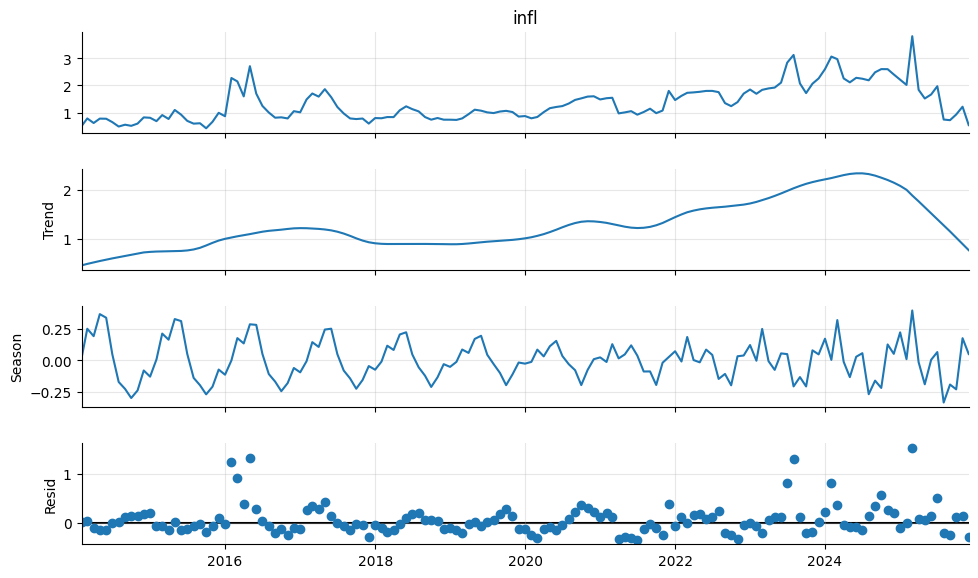

Strength of (trend, seasonality), 0-1:  full sample (0.76, 0.28) |  2014-2022 (0.57, 0.33)

Average STL seasonal effect on m/m inflation, percentage points, by calendar month:
date   Jan  Feb  Mar   Apr   May   Jun   Jul   Aug   Sep   Oct   Nov   Dec
pp    0.01 -0.0  0.2  0.06  0.11  0.17  0.05 -0.14 -0.14 -0.23 -0.06 -0.01


In [11]:
# 1d. STL decomposition of monthly inflation (seam month interpolated) and strength of trend and seasonality
stl = STL(infl_p, period=12, seasonal=13, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(10, 6.5); plt.show()

def strength_features(s, period=12):
    r = STL(s, period=period, seasonal=13, robust=True).fit()
    ft = max(0, 1 - r.resid.var() / (r.trend + r.resid).var()); fs = max(0, 1 - r.resid.var() / (r.seasonal + r.resid).var())
    return round(ft, 2), round(fs, 2)
print("Strength of (trend, seasonality), 0-1:  full sample", tuple(map(float, strength_features(infl_p))), "|  2014-2022", tuple(map(float, strength_features(infl_p.loc[:"2022"]))))
seas_by_month = stl.seasonal.groupby(stl.seasonal.index.month).mean()
print("\nAverage STL seasonal effect on m/m inflation, percentage points, by calendar month:")
print(seas_by_month.rename(index=lambda m: pd.Timestamp(2000, m, 1).strftime("%b")).round(2).to_frame("pp").T.to_string())

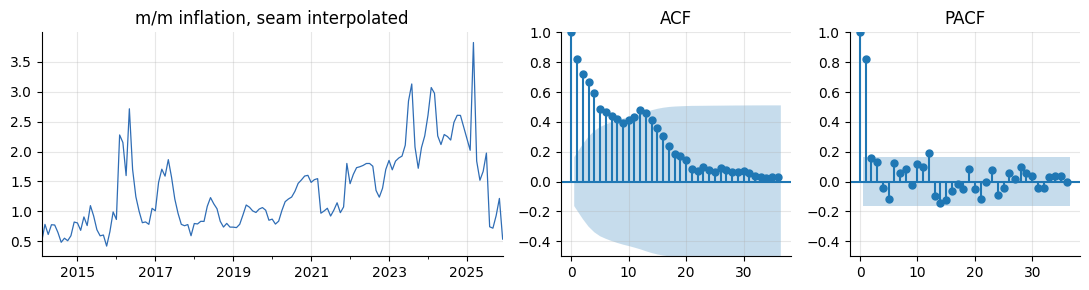

ADF p = 0.304, KPSS p = 0.010   (raw m/m series: level shifts make KPSS reject constant-mean stationarity)
After removing the two regime means: ADF p = 0.081, KPSS p = 0.067
ACF of regime-demeaned inflation at lags 1, 3, 6, 12, 24: [ 0.64  0.37 -0.04  0.29  0.02]


/tmp/ipykernel_3571/579519661.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  adf_p = adfuller(infl_p, autolag="AIC")[1]; kpss_p = kpss(infl_p, regression="c", nlags="auto")[1]


In [12]:
# 1e. Autocorrelation and stationarity of monthly inflation
fig, axes = plt.subplots(1, 3, figsize=(11, 3), gridspec_kw={"width_ratios": [2, 1, 1]})
infl_p.plot(ax=axes[0], lw=0.9, color=BLUE, title="m/m inflation, seam interpolated"); axes[0].set_xlabel("")
plot_acf(infl_p, lags=36, ax=axes[1], title="ACF"); plot_pacf(infl_p, lags=36, ax=axes[2], title="PACF", method="ywm")
for ax in axes[1:]: ax.set_ylim(-0.5, 1)
plt.tight_layout(); plt.show()

adf_p = adfuller(infl_p, autolag="AIC")[1]; kpss_p = kpss(infl_p, regression="c", nlags="auto")[1]
X_reg = pd.DataFrame({"post_reform": (infl_p.index >= "2023-06-01").astype(float), "rebased": (infl_p.index >= "2025-02-01").astype(float)}, index=infl_p.index)
demeaned = sm.OLS(infl_p, sm.add_constant(X_reg)).fit().resid
print(f"ADF p = {adf_p:.3f}, KPSS p = {kpss_p:.3f}   (raw m/m series: level shifts make KPSS reject constant-mean stationarity)")
print(f"After removing the two regime means: ADF p = {adfuller(demeaned, autolag='AIC')[1]:.3f}, KPSS p = {kpss(demeaned, regression='c', nlags='auto')[1]:.3f}")
acf_vals = sm.tsa.acf(demeaned, nlags=24)
print("ACF of regime-demeaned inflation at lags 1, 3, 6, 12, 24:", np.round(acf_vals[[1, 3, 6, 12, 24]], 2))

The index is modelled through monthly log changes because year-on-year inflation is a twelve-month moving sum, which is smooth by construction and carries arithmetic base effects. The mean of monthly inflation moves in regimes: 0.98% (2014 to 2019), 1.41% (2020 to May 2023), 2.42% (June 2023 to December 2024, after subsidy removal and FX unification), and 1.54% in February to December 2025 under the rebased basket, falling to 1.02% over the last six months of 2025. The January 2025 observation (-2.88%) is a definitional step from the NBS rebasing, not deflation: the index-implied year-on-year for January 2025 (27.61%) differs from the announced 24.5%, while the two agree at 15.15% by December 2025, as the Context Note states.
Seasonality is weak (STL strength 0.28 over the full sample; calender-month effects lie between -0.23 and +0.20 percentage points), whereas trend/level strength is 0.76. The raw monthly series is non-stationary through level-shifts (ADF p=0.304; KPSS p= 0.081; KPSS p= 0.067), so we treat inflation as stationary around regime means and model the regimes with dummies rather than differencing. Autocorrelation is short-lived (ACF 0.64 at lag1, 0.37 at lag 3) with a residual annual echo (0.29 at lag 12).

**Implication for the horizon**
With an AR(1) coefficient of about 0.71, a shock loses half its effect in roughly two months; beyond a quarter or so the forecast is essentially the regime mean. Regimes changes themselves are not forecastable from the series. Useful forecast information is therefore short-lived, and uncertainty about the level in the budget year is dominated by regime risk (Section 3, horizon plot).

## 2. Methods considered and rejected

*benchmark; decomposition-based; ARIMA; SARIMA; regression with ARIMA errors*

In [13]:
#2a. Intervention dummies from the Context Note and the candidate methods as fit-and-forecast functions
def dummies(idx):
    """Known events. Effects are on m/m inflation, so a level shift in log CPI is a one-month pulse here."""
    return pd.DataFrame({
        "step_2306":  (idx >= "2023-06-01").astype(float),                          # post-reform regime (subsidy removal + FX unification)
        "pulse_2307": ((idx >= "2023-07-01") & (idx <= "2023-08-01")).astype(float),  # pass-through spike, Jul-Aug 2023
        "seam_2501":  (idx == SEAM).astype(float),                                   # rebasing seam (level shift in log CPI)
        "step_2502":  (idx >= "2025-02-01").astype(float),                          # rebased-basket / disinflation regime
    }, index=idx)

fidx = lambda tr, h: pd.date_range(tr.index[-1], periods=h + 1, freq="MS")[1:]
P = lambda tr: infl_p.reindex(tr.index)           # seam-interpolated history for methods that cannot carry a dummy

def regarima_fit(tr, order=(1, 0, 0), sorder=(1, 0, 0, 12), exog_extra=None):
    """Regression on the event dummies with SARIMA errors. A dummy enters only once the training data can identify it
    (pulses: >=1 month; regime steps: >=3 months), so the function is usable at every rolling origin."""
    X = dummies(tr.index); keep = [c for c in X if X[c].sum() >= (3 if c.startswith("step") else 1)]
    X = X[keep]
    if exog_extra is not None: X = X.join(exog_extra.reindex(tr.index))
    return ARIMA(tr, exog=X, order=order, seasonal_order=sorder).fit(), keep

def regarima_fc(tr, h, alpha=None, **kw):
    fit, keep = regarima_fit(tr, **kw); Xf = dummies(fidx(tr, h))[keep]
    f = fit.get_forecast(h, exog=Xf)
    if alpha is None: return f.predicted_mean.values
    ci = f.conf_int(alpha=alpha); return f.predicted_mean.values, ci.iloc[:, 0].values, ci.iloc[:, 1].values

def stl_arima_fc(tr, h):
    tr = P(tr); r = STL(tr, period=12, seasonal=13, robust=True).fit(); sa = tr - r.seasonal
    return ARIMA(sa, order=(1, 0, 1)).fit().forecast(h).values + np.tile(r.seasonal[-12:].values, 2)[:h]

METHODS = {
    "Naive":                     lambda tr, h: np.repeat(P(tr).iloc[-1], h),
    "Seasonal naive":            lambda tr, h: np.tile(P(tr).iloc[-12:].values, 2)[:h],
    "Mean of last 12 months":    lambda tr, h: np.repeat(P(tr).iloc[-12:].mean(), h),
    "STL + ARIMA(1,0,1)":        stl_arima_fc,
    "ARIMA(1,0,1)":              lambda tr, h: ARIMA(P(tr), order=(1, 0, 1)).fit().forecast(h).values,
    "ARIMA(0,1,1)":              lambda tr, h: ARIMA(P(tr), order=(0, 1, 1)).fit().forecast(h).values,
    "SARIMA(1,0,0)(1,0,0)12":    lambda tr, h: ARIMA(P(tr), order=(1, 0, 0), seasonal_order=(1, 0, 0, 12)).fit().forecast(h).values,
    "RegARIMA: dummies + SAR errors": lambda tr, h: regarima_fc(tr, h),
}
print("Candidate methods:", ", ".join(METHODS))

Candidate methods: Naive, Seasonal naive, Mean of last 12 months, STL + ARIMA(1,0,1), ARIMA(1,0,1), ARIMA(0,1,1), SARIMA(1,0,0)(1,0,0)12, RegARIMA: dummies + SAR errors


In [ ]:
# 2b. Identification on the full sample: information criteria and residual checks
X_full = dummies(infl.index)
rows = []
cands = [("ARIMA(1,0,1), no dummies", infl_p, None, (1, 0, 1), (0, 0, 0, 0)),
         ("SARIMA(1,0,0)(1,0,0)12, no dummies", infl_p, None, (1, 0, 0), (1, 0, 0, 12)),
         ("RegARIMA dummies, AR(1) errors", infl, X_full, (1, 0, 0), (0, 0, 0, 0)),
         ("RegARIMA dummies, ARMA(1,1) errors", infl, X_full, (1, 0, 1), (0, 0, 0, 0)),
         ("RegARIMA dummies, (1,0,0)(1,0,0)12 errors", infl, X_full, (1, 0, 0), (1, 0, 0, 12)),
         ("RegARIMA dummies, (2,0,0)(1,0,0)12 errors", infl, X_full, (2, 0, 0), (1, 0, 0, 12)),
         ("RegARIMA dummies, (1,0,1)(1,0,1)12 errors", infl, X_full, (1, 0, 1), (1, 0, 1, 12))]
for name, y_, X_, o, so in cands:
    f = ARIMA(y_, exog=X_, order=o, seasonal_order=so).fit()
    k = o[0] + o[2] + so[0] + so[2]
    lb = acorr_ljungbox(f.resid[13:], lags=[24], model_df=k, return_df=True).lb_pvalue.iloc[0]
    rows.append({"model": name, "AICc": f.aicc, "BIC": f.bic, "LB(24) p": lb, "sigma": np.sqrt(f.params["sigma2"])})
print("Note: the two no-dummy rows are fitted to the interpolated series, so their AICc is not comparable with the dummy rows.")
print(pd.DataFrame(rows).set_index("model").round(3).to_string())

try:
    import pmdarima as pm
    auto = pm.auto_arima(infl, X=X_full, seasonal=True, m=12, stepwise=True, information_criterion="aicc", suppress_warnings=True)
    print("\npmdarima auto_arima with the dummies chooses:", auto.order, auto.seasonal_order)
except Exception as e:
    print("pmdarima not available:", e)

Note: the two no-dummy rows are fitted to the interpolated series, so their AICc is not comparable with the dummy rows.
                                              AICc      BIC  LB(24) p  sigma
model                                                                       
ARIMA(1,0,1), no dummies                   125.317  136.879     0.098  0.363
SARIMA(1,0,0)(1,0,0)12, no dummies         117.496  129.058     0.183  0.351
RegARIMA dummies, AR(1) errors             118.721  138.631     0.302  0.347
RegARIMA dummies, ARMA(1,1) errors         117.965  140.593     0.102  0.343
RegARIMA dummies, (1,0,0)(1,0,0)12 errors  105.715  128.343     0.456  0.326
RegARIMA dummies, (2,0,0)(1,0,0)12 errors  103.997  129.309     0.348  0.321
RegARIMA dummies, (1,0,1)(1,0,1)12 errors  102.442  130.403     0.536  0.315


In [ ]:
# 2c. Regression with ARIMA errors on the exchange rate and oil price: do they earn their place?
reg_df = pd.DataFrame({"infl": infl, "d_fx_l1": 100 * np.log(fx).diff().shift(1), "d_fx_l2": 100 * np.log(fx).diff().shift(2),
                       "d_fx_l3": 100 * np.log(fx).diff().shift(3), "d_oil_l1": 100 * np.log(bonny).diff().shift(1)}).dropna()
Xr = reg_df.drop(columns="infl").join(dummies(reg_df.index))
ols = sm.OLS(reg_df["infl"], sm.add_constant(Xr)).fit()
print(f"OLS Durbin-Watson = {durbin_watson(ols.resid):.2f} -> autocorrelated errors, so an ARMA error model is needed")
regx = ARIMA(reg_df["infl"], exog=Xr, order=(1, 0, 0), seasonal_order=(1, 0, 0, 12)).fit()
print(regx.summary().tables[1])
fx_cols = ["d_fx_l1", "d_fx_l2", "d_fx_l3"]
fx_sum = regx.params[fx_cols].sum(); fx_se = np.sqrt(regx.cov_params().loc[fx_cols, fx_cols].values.sum())
w = regx.wald_test(" , ".join(f"{c} = 0" for c in fx_cols + ["d_oil_l1"]), scalar=True)
print(f"Sum of FX pass-through coefficients (lags 1-3) = {fx_sum:.3f} (se {fx_se:.3f}): a 10% depreciation adds about {10*fx_sum:.2f} pp to m/m inflation over three months")
print(f"Joint Wald test that FX and oil coefficients are all zero: p = {float(w.pvalue):.3f}")
base = ARIMA(reg_df["infl"], exog=dummies(reg_df.index), order=(1, 0, 0), seasonal_order=(1, 0, 0, 12)).fit()
print(f"AICc with FX and oil = {regx.aicc:.1f}   vs   dummies only on the same sample = {base.aicc:.1f}")

In [ ]:
# 2d. The chosen model: regression on the event dummies with SARIMA(1,0,0)(1,0,0)12 errors, fitted to Feb 2014 - Dec 2025
final, final_cols = regarima_fit(infl)
print(final.summary().tables[1])
lb = acorr_ljungbox(final.resid[13:], lags=[12, 24], model_df=2, return_df=True); print("\nLjung-Box on residuals:\n", lb.round(3).to_string())
p = final.params
mu_2025 = p["const"] + p["step_2306"] + p["step_2502"]
print(f"\nImplied regime means (m/m %): pre-reform {p['const']:.2f}; post-reform {p['const'] + p['step_2306']:.2f}; rebased 2025 regime {mu_2025:.2f}"
      f"  (= {100*(np.exp(12*mu_2025/100)-1):.1f}% a year)")
print(f"Estimated seam effect = {p['seam_2501']:.2f} pp in Jan 2025 (the size of the definitional step, absorbed by the dummy)")
fig = final.plot_diagnostics(figsize=(10, 5.5))
plt.tight_layout()
plt.show()

**Commentary: Benchmarks**.
The naive forecast is retained as the benchmark. The seasonal naive and the 12-month means were rejected as forecasting methods: seasonality is weak and the seasonal naive is the worst performer in rolling-origin evaluation (MAE 0.796, 1.22 times naive). ARIMA without interventions cannot represent the 2023 and 2025 regime changes; ARIMA(1,0,1) is the weakest candidate out of sample (1.12 times naive). ARIMA(0,1,1) is statistically equivalent to naive(1.003), which is what auto_arima with the dummies also selects, (0,1,1)(0,0,1)12, and adds nothing. STL + ARIMA and SARIMA without dummies (each 1.03 times naive) do not improve on naive and are fitted to a series whose seam month had to be interpolated. Regression on exchange rate and oil. Lagged FX and oil terms were tested on the same sample as a dummies-only model. The FX coefficients are wrong-signed (lag 1: -0.009, p=0.034; joint Wald test p = 0.026), AiCc worsens (109.3 against 104.0), and that fit raised a convergence warning. Both regressors would also need assumed paths over the forecast period. We therefore do not carry them, and express exchange-rate risk through the scenario in Section 6.
**Chosen model**: regression on event dummies (post-reform step June 2023, pulse July to August 2023, January 2025 seam, rebased-regime step from February 2025) with SARIMA (1,0,0)(1,0,0)12 errors. The dummies are the interventions the Context Note identifies; the estimated step_2306 is +0.62 (p=0.021) and step_2502 is -0.73 (p=0.003). Implied regime means are 1.21%(pre-reform), 1.83% (post-reform) and 1.10% per month (14.1% per year) for the rebased regime. Residuals show no remaining autocorrelation (Ljung Box p = 0.208 at lag 12, 0.0456 at lag 24). It has the lowest BIC(128.3); two richer specifications have AICc 1.7 to 3.3 lower, a difference we judge too small to justify extra parameters on 143 obsrvations. The seam coefficient (-5.41pp) is measured relative to the model's conditional expectation, not the observed -2.88% change.

## 3. Evaluation on the last 12 months against naive

*MAE / MASE; coverage*

In [ ]:

# 3a. Hold-out: estimate on data to Dec 2024, forecast Jan-Dec 2025, score against the actuals
def accuracy(actual, forecast, train, m=1):
    """Lab 13 accuracy(); MASE is scaled by the in-sample one-step naive MAE of the (seam-interpolated) training series."""
    e = actual - forecast; q = np.mean(np.abs(train.values[m:] - train.values[:-m]))
    return {"MAE": np.nanmean(np.abs(e)), "RMSE": np.sqrt(np.nanmean(e**2)), "MASE": np.nanmean(np.abs(e)) / q, "mean error": np.nanmean(e)}

ORIGIN = pd.Timestamp("2024-12-01"); train, test = infl[:ORIGIN], infl.loc["2025"]
act = test.values.copy(); act[test.index == SEAM] = np.nan          # the seam month is not an inflation outcome: not scored
act_cum = infl_p.loc["2025"].sum()                                       # 2025 cumulative m/m inflation, seam interpolated
hold, hold_fc = {}, {}
for name, fn in METHODS.items():
    fc = np.asarray(fn(train, 12)); hold_fc[name] = fc
    r = accuracy(act, fc, P(train)); r["12-m cumulative error (pp)"] = act_cum - fc.sum(); hold[name] = r
hold = pd.DataFrame(hold).T.sort_values("MASE")
hold["MAE relative to naive"] = hold["MAE"] / hold.loc["Naive", "MAE"]
print(f"Hold-out Jan-Dec 2025 (Jan 2025 seam not scored). Actual cumulative 2025 m/m inflation (seam interpolated) = {act_cum:.1f}%")
print(hold.round(3).to_string())

ax = infl_p.loc["2023":].plot(figsize=(10, 3.6), color="black", lw=1.3, label="actual (seam interpolated)")
for name, c, ls in [("Naive", GREY, ":"), ("ARIMA(1,0,1)", BLUE, "--"), ("RegARIMA: dummies + SAR errors", GOLD, "-")]:
    pd.Series(hold_fc[name], index=test.index).plot(ax=ax, color=c, ls=ls, lw=2, label=name)
ax.axvline(ORIGIN, color=GREY, lw=0.8); ax.legend(fontsize=8); ax.set_xlabel(""); ax.set_title("Hold-out forecasts of m/m inflation from Dec 2024"); plt.show()

In [ ]:
# 3b. Interval coverage on the hold-out (80% and 95%)
def naive_pi(tr, h, alpha):
    tr = P(tr); mean_ = np.repeat(tr.iloc[-1], h); lo, hi = [], []
    for k in range(1, h + 1):
        ch = (tr - tr.shift(k)).dropna(); lo.append(mean_[k-1] + ch.quantile(alpha / 2)); hi.append(mean_[k-1] + ch.quantile(1 - alpha / 2))
    return mean_, np.array(lo), np.array(hi)
cov_rows = {}
for name, fn in [("Naive (empirical PI)", naive_pi), ("RegARIMA: dummies + SAR errors", lambda tr, h, alpha: regarima_fc(tr, h, alpha=alpha))]:
    r = {}
    for a in (0.2, 0.05):
        m_, lo, hi = fn(train, 12, a); ok = ~np.isnan(act)
        r[f"{int(100*(1-a))}% coverage"] = np.mean((act[ok] >= lo[ok]) & (act[ok] <= hi[ok])); r[f"{int(100*(1-a))}% mean width"] = np.mean(hi - lo)
    cov_rows[name] = r
print("Hold-out coverage over the 11 scored months of 2025:"); print(pd.DataFrame(cov_rows).T.round(2).to_string())

In [ ]:
# 3c. Rolling-origin evaluation over the last three years (origins Dec 2022 - Nov 2025, horizons 1-12)
def rolling_origin(y, fit_forecast, h, origins):
    """rolling_origin(), adapted: errors are NaN beyond the end of the data and at the seam month."""
    errs = []
    for o in origins:
        fc = np.asarray(fit_forecast(y[:o], h)); a = y[o:].iloc[1:h + 1]
        e = np.full(h, np.nan); e[:len(a)] = a.values - fc[:len(a)]; e[:len(a)][a.index == SEAM] = np.nan; errs.append(e)
    return pd.DataFrame(errs, index=origins, columns=[f"h={k}" for k in range(1, h + 1)])

origins = pd.date_range("2022-12-01", "2025-11-01", freq="MS")
q_scale = np.mean(np.abs(np.diff(infl_p.loc[:"2022-12"].values)))         # MASE scale: in-sample naive MAE before the first origin
RO = {name: rolling_origin(infl, fn, 12, origins) for name, fn in METHODS.items()}
mase_h = pd.DataFrame({n: E.abs().mean() / q_scale for n, E in RO.items()})
summary = pd.DataFrame({"MAE h=1-12": {n: np.nanmean(np.abs(E.values)) for n, E in RO.items()},
                        "MAE h=1-3":  {n: np.nanmean(np.abs(E.iloc[:, :3].values)) for n, E in RO.items()},
                        "MAE h=7-12": {n: np.nanmean(np.abs(E.iloc[:, 6:].values)) for n, E in RO.items()},
                        "bias (actual - fc)": {n: np.nanmean(E.values) for n, E in RO.items()}})
summary["MASE"] = summary["MAE h=1-12"] / q_scale; summary["relative to naive"] = summary["MAE h=1-12"] / summary.loc["Naive", "MAE h=1-12"]
print(f"{len(origins)} origins; scored errors per method = {int(RO['Naive'].notna().sum().sum())}")
print(summary.sort_values("MAE h=1-12").round(3).to_string())
ax = mase_h[["Naive", "Mean of last 12 months", "ARIMA(1,0,1)", "SARIMA(1,0,0)(1,0,0)12", "RegARIMA: dummies + SAR errors"]].plot(figsize=(9, 3.4), marker="o", ms=3)
ax.set_xlabel("forecast horizon (months)"); ax.set_ylabel("MASE"); ax.set_title("Rolling-origin MASE by horizon, origins Dec 2022 - Nov 2025"); ax.legend(fontsize=8); plt.show()

from scipy import stats as _st
def diebold_mariano(e1, e2, h=1):
    ok = ~np.isnan(e1) & ~np.isnan(e2); d = np.abs(e1[ok]) - np.abs(e2[ok]); n = len(d); dbar = d.mean()
    gamma = [np.sum((d[k:] - dbar) * (d[:n - k] - dbar)) / n for k in range(h)]
    lrv = gamma[0] + 2 * sum((1 - k / h) * gamma[k] for k in range(1, h)); dm = dbar / np.sqrt(lrv / n)
    return dm, 2 * (1 - _st.norm.cdf(abs(dm)))
for hh in [1, 6, 12]:
    dm, pv = diebold_mariano(RO["Naive"][f"h={hh}"].values, RO["RegARIMA: dummies + SAR errors"][f"h={hh}"].values, hh)
    print(f"Diebold-Mariano, naive vs chosen model, h={hh:2d}: DM = {dm:5.2f}, p = {pv:.3f}  (positive = chosen model more accurate)")

In [ ]:
# 3d. Calibrating the uncertainty: coverage of the 12-month cumulative inflation range from simulated paths
# The budget cares about cumulative inflation over a year, so coverage is checked on the 12-month sum of m/m inflation.
# Simulated paths from the fitted model are widened by a factor k (deviations around the mean scaled by k, which for a
# linear Gaussian model is the same as scaling the innovations by k). We look for the smallest k that delivers nominal coverage.
def sim_paths(fit, keep, tr, h, n=2000, seed=SEED):
    Xf = dummies(fidx(tr, h))[keep]
    np.random.seed(seed)
    sims = fit.simulate(nsimulations=h, repetitions=n, anchor="end", exog=Xf)
    sims = np.asarray(sims).reshape(h, n).T                                   # n paths x h months
    return fit.get_forecast(h, exog=Xf).predicted_mean.values, sims

cal_origins = pd.date_range("2022-12-01", "2024-12-01", freq="MS")             # origins with a full 12 months ahead
K = [1.0, 1.25, 1.5, 1.75, 2.0, 2.5]; rec = []
for o in cal_origins:
    tr = infl[:o]; fit, keep = regarima_fit(tr); mean_, sims = sim_paths(fit, keep, tr, 12)
    cum_act = infl_p[o:].iloc[1:13].sum(); dev = sims.sum(1) - mean_.sum()
    for k in K:
        c = mean_.sum() + k * dev
        rec.append({"origin": o, "k": k, "in80": np.quantile(c, .1) <= cum_act <= np.quantile(c, .9),
                    "in95": np.quantile(c, .025) <= cum_act <= np.quantile(c, .975), "cum_err": cum_act - mean_.sum(), "sd_cum": np.std(dev)})
cal = pd.DataFrame(rec)
cov_tab = cal.groupby("k")[["in80", "in95"]].mean().rename(columns={"in80": "80% coverage", "in95": "95% coverage"})
print(f"{len(cal_origins)} overlapping 12-month windows. Coverage of the 12-month cumulative range by widening factor k:")
print(cov_tab.round(2).to_string())
z = cal[cal.k == 1.0]; ratio = np.sqrt(np.mean((z.cum_err / z.sd_cum) ** 2))
print(f"\nRMS of standardised 12-month cumulative errors = {ratio:.2f} (1.0 would mean the model's own uncertainty is right)")
K_WIDEN = round(float(ratio), 2)      # scale the model's spread to the spread of errors actually observed
print(f"Widening factor adopted for the forecast: k = {K_WIDEN} (the RMS ratio). The grid shows this restores roughly 70-80% coverage of the 80% range;")
print("only 25 overlapping windows (about two independent years) inform it, so it is a judgement anchored in the backtest, not a precise estimate.")

Commentary:

## 4. Twelve-month forecast with 80% and 95% ranges, converted to year-on-year

In [ ]:
#4a. Forecast m/m inflation from Dec 2025, simulate CPI paths, and convert to year-on-year
#Jan 2026 - Dec 2027: 12 months for the forecast + the 2027 budget year
H = 24
mean_m, sims = sim_paths(final, final_cols, infl, H, n=10000)

#widened paths
sims_w = mean_m + K_WIDEN * (sims - mean_m)
fut = fidx(infl, H)


 #simulated log CPI, n x H
logc_hist = np.log(cpi)
paths = np.log(cpi.iloc[-1]) + np.cumsum(sims_w, axis=1) / 100
cpi_paths = pd.DataFrame(np.exp(paths), columns=fut)
hist_block = pd.DataFrame(np.tile(cpi.values, (len(cpi_paths), 1)), columns=cpi.index)

#last 12 actual months + simulated future
allp = pd.concat([hist_block[cpi.index[-12:]], cpi_paths], axis=1)
yoy_paths = 100 * (allp.iloc[:, 12:].values / allp.iloc[:, :-12].values - 1)
yoy_paths = pd.DataFrame(yoy_paths, columns=fut)

def q(df, qs=(0.025, 0.1, 0.5, 0.9, 0.975)): return df.quantile(qs).T.set_axis(["lo95", "lo80", "median", "hi80", "hi95"], axis=1)
mom_tab = pd.DataFrame({"m/m point %": mean_m}, index=fut).join(q(pd.DataFrame(sims_w, columns=fut)).add_prefix("m/m ")[["m/m lo80", "m/m hi80"]])
yoy_tab = q(yoy_paths)
fc_tab = mom_tab.join(yoy_tab.add_prefix("YoY "))
print("Twelve-month forecast, Jan-Dec 2026 (widened ranges):")
print(fc_tab.loc["2026"].round(2).to_string())

In [ ]:
#4b. Budget-relevant summaries: December year-on-year and the calendar-year average
def year_avg_infl(year):
    """Average CPI in `year` over average CPI in year-1 - the measure that scales a year's spending."""
    cur = cpi_paths[[c for c in fut if c.year == year]].mean(1)
    prev_cols = [c for c in fut if c.year == year - 1]
    prev = cpi_paths[prev_cols].mean(1) if prev_cols else pd.Series(cpi.loc[str(year - 1)].mean(), index=cpi_paths.index)
    return 100 * (cur / prev - 1)
summ = pd.DataFrame({
    "Dec 2026 YoY": yoy_paths[pd.Timestamp("2026-12-01")], "2026 average": year_avg_infl(2026),
    "Dec 2027 YoY": yoy_paths[pd.Timestamp("2027-12-01")], "2027 average": year_avg_infl(2027)}).quantile([0.025, 0.1, 0.5, 0.75, 0.8, 0.9, 0.975]).T
summ.columns = ["2.5%", "10%", "median", "75%", "80%", "90%", "97.5%"]
print(f"Distribution of headline inflation, in % (ranges widened by k = {K_WIDEN:.2f}):"); print(summ.round(1).to_string())

# For comparison: the model's own (unwidened) ranges for the 2027 average
cpi_raw = pd.DataFrame(np.exp(np.log(cpi.iloc[-1]) + np.cumsum(sims, axis=1) / 100), columns=fut)
raw27 = 100 * (cpi_raw[[c for c in fut if c.year == 2027]].mean(1) / cpi_raw[[c for c in fut if c.year == 2026]].mean(1) - 1)
print(f"Unwidened model ranges for the 2027 average: 80% {np.quantile(raw27, .1):.1f}-{np.quantile(raw27, .9):.1f}%, 95% {np.quantile(raw27, .025):.1f}-{np.quantile(raw27, .975):.1f}%  (too narrow: Section 3)")
point_dec26 = 100 * (np.exp(mean_m[:12].sum() / 100) - 1)
print(f"\nPoint (mean-path) Dec 2026 YoY = {point_dec26:.1f}%;  long-run m/m level the model reverts to = {mu_2025:.2f}% a month")

# Base effect in early 2026: YoY in Jan 2026 drops the Jan 2025 seam month (-2.9%) from its 12-month window.
yoy_dec25 = yoy.iloc[-1]; yoy_jan26 = yoy_tab.loc["2026-01-01", "median"]
print(f"Arithmetic base effect: YoY Dec 2025 = {yoy_dec25:.1f}% -> Jan 2026 median {yoy_jan26:.1f}%; "
      f"of the {yoy_jan26 - yoy_dec25:+.1f} pp move, about {-infl[SEAM]:.1f} pp comes from the seam month leaving the window, not from prices")

In [ ]:
#4c. Fan chart of year-on-year inflation   [forecast plot]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]; infl.loc["2023":].plot(ax=ax, color="black", lw=1.2, label="actual m/m")
m_ = pd.Series(mean_m, index=fut).loc["2026"]; lo80 = mom_tab.loc["2026", "m/m lo80"]; hi80 = mom_tab.loc["2026", "m/m hi80"]
m_.plot(ax=ax, color=GOLD, lw=2, label="forecast"); ax.fill_between(m_.index, lo80, hi80, color=GOLD, alpha=0.3, label="80% range (widened)")
ax.axhline(mu_2025, color=GREY, ls="--", lw=0.8, label=f"rebased-regime mean {mu_2025:.2f}%"); ax.set_title("Monthly inflation, %"); ax.legend(fontsize=7); ax.set_xlabel("")
ax = axes[1]; yoy.loc["2023":].plot(ax=ax, color="black", lw=1.2, label="actual YoY (from index)")
yt = yoy_tab.loc[:"2026-12-01"]
yt["median"].plot(ax=ax, color=GOLD, lw=2, label="median forecast")
ax.fill_between(yt.index, yt["lo95"], yt["hi95"], color=GOLD, alpha=0.15, label="95%"); ax.fill_between(yt.index, yt["lo80"], yt["hi80"], color=GOLD, alpha=0.35, label="80%")
ax.set_title("Year-on-year headline inflation, %"); ax.legend(fontsize=7); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("cs1_fan_chart.png", dpi=200, bbox_inches="tight"); plt.show()

Commentary:

## 5. The budget assumption and the asymmetry of consequences

*point, conservative upper value, or other: justify*

In [ ]:
# 5a. Choosing the assumption under asymmetric loss (pinball / newsvendor rule)
# If under-assuming inflation by 1 pp costs c_u and over-assuming by 1 pp costs c_o, the assumption that minimises expected loss
# is the quantile c_u / (c_u + c_o) of the forecast distribution.
# the 2027 budget year, average over average
target = year_avg_infl(2027)
rows = []
for ratio in [1, 2, 3, 4]:
    tau = ratio / (ratio + 1); a = np.quantile(target, tau)
    loss = lambda x: np.mean(np.where(target > x, ratio * (target - x), (x - target)))
    rows.append({"cost of under- vs over-assuming": f"{ratio}:1", "optimal quantile": tau, "assumption, 2027 avg %": a,
                 "P(actual exceeds it)": np.mean(target > a), "expected loss vs point forecast": loss(a) / loss(np.median(target))})
loss_tab = pd.DataFrame(rows).set_index("cost of under- vs over-assuming"); print(loss_tab.round(2).to_string())

assume = np.quantile(target, 0.75)
print(f"\nRecommended 2027 assumption (75th percentile, cost ratio 3:1): {assume:.1f}%  -> rounded {np.round(assume):.0f}%")
print(f"Median 2027 average: {np.median(target):.1f}%;  80% range {np.quantile(target, .1):.1f}-{np.quantile(target, .9):.1f}%;  "
      f"95% range {np.quantile(target, .025):.1f}-{np.quantile(target, .975):.1f}%")
print(f"Probability 2027 average inflation exceeds the assumption: {np.mean(target > np.round(assume)):.0%}")

In [ ]:
# 5b. What the assumption means in naira: a line item of N1bn at 2026 prices   [illustration for the Permanent Secretary]
line = 1.0
for label, v in [("point (median)", np.median(target)), ("recommended (75th pct)", np.round(assume)), ("90th percentile", np.quantile(target, .9))]:
    shortfall = line * (np.quantile(target, .9) - v) / 100
    print(f"{label:25s} {v:5.1f}%  -> provision N{line*(1+v/100):.3f}bn;  shortfall if the 90th-percentile outcome occurs: N{max(shortfall,0)*1000:.0f}m")

Commentary:

## 6. Risks and indicators to monitor

*Reasons the forecast could be wrong*

In [ ]:
#6a. Scenario: a reversal back to the post-reform regime from January 2027
#The FX and oil regressors were rejected in Section 2c (wrong-signed, insignificant pass-through once the regimes are dummied),
# so the exchange-rate risk is expressed through the one pass-through episode the data identifies: the June 2023 reforms.
# Scenario: from Jan 2027 the rebased-regime step is undone (+|step_2502|) and the Jul-Aug 2023 pulse repeats in Jan-Feb 2027.

shift = np.zeros(H); jan27 = list(fut).index(pd.Timestamp("2027-01-01"))
shift[jan27:] += -p["step_2502"]; shift[jan27:jan27 + 2] += p["pulse_2307"]
cpi_scn = pd.DataFrame(np.exp(np.log(cpi.iloc[-1]) + np.cumsum(sims_w + shift, axis=1) / 100), columns=fut)
scn27 = 100 * (cpi_scn[[c for c in fut if c.year == 2027]].mean(1) / cpi_scn[[c for c in fut if c.year == 2026]].mean(1) - 1)
print(f"2027 average inflation, baseline median {np.median(target):.1f}%  ->  reversal scenario median {np.median(scn27):.1f}% "
      f"(80% range {np.quantile(scn27, .1):.1f}-{np.quantile(scn27, .9):.1f}%)")
print(f"Probability the recommended {np.round(assume):.0f}% assumption is exceeded: baseline {np.mean(target > np.round(assume)):.0%}, scenario {np.mean(scn27 > np.round(assume)):.0%}")

# Early-warning thresholds: monthly inflation that, sustained for three months, puts the 2027 average above the assumption
thr = 100 * np.log(1 + np.round(assume) / 100) / 12
print(f"\nTrigger: a 3-month average m/m rate above {thr:.2f}% is the pace consistent with {np.round(assume):.0f}% a year -> revise.")
print("Recent official NGN/USD m/m changes (%, positive = naira depreciation), an indicator to watch:")
print((100 * np.log(fx).diff()).loc["2025-07":].round(1).to_frame("d log FX %").T.to_string())

In [ ]:
# 6b. Out-of-sample check against NBS releases for 2026 (published after the course snapshot ends)
# These are NBS figures as reported in the press; VERIFY against the NBS CPI and Inflation Reports before quoting.
nbs_2026 = pd.DataFrame({"NBS YoY %": {"2026-01-01": 15.10, "2026-02-01": 15.06, "2026-04-01": 15.69, "2026-05-01": 15.93, "2026-06-01": 15.91},
                         "NBS CPI": {"2026-01-01": 127.4, "2026-05-01": 140.7, "2026-06-01": 143.0},
                         "NBS m/m %": {"2026-01-01": -2.88, "2026-05-01": 1.75, "2026-06-01": 1.66}})
nbs_2026.index = pd.to_datetime(nbs_2026.index)
chk = nbs_2026.join(yoy_tab[["lo80", "median", "hi80"]].add_prefix("model YoY ")).join(mom_tab[["m/m point %", "m/m hi80"]])
print(chk.round(2).to_string())
pace = 100 * np.log(143.0 / 127.4) / 5
print(f"\nNBS index Jan -> Jun 2026 implies {pace:.2f}% a month (annualised {100*(np.exp(12*pace/100)-1):.0f}%), "
      f"against the model's {mean_m[1:6].mean():.2f}% point and {mom_tab['m/m hi80'].iloc[1:6].mean():.2f}% upper-80% for Feb-Jun 2026.")
print("January 2026 repeated a ~-2.9% m/m step like the January 2025 seam, which the model (following the Context Note) treated as a one-off.")
ax = yoy.loc["2024":].plot(figsize=(9, 3.4), color="black", lw=1.2, label="YoY from the snapshot index")
yt = yoy_tab.loc[:"2026-12-01"]; yt["median"].plot(ax=ax, color=GOLD, lw=2, label="model median (from Dec 2025)")
ax.fill_between(yt.index, yt["lo80"], yt["hi80"], color=GOLD, alpha=0.3, label="80% range (widened)")
ax.scatter(nbs_2026.index, nbs_2026["NBS YoY %"], color=RED, zorder=5, label="NBS outturn 2026 (press-reported)")
ax.set_title("Out-of-sample check: model vs NBS releases for 2026"); ax.legend(fontsize=7); ax.set_xlabel(""); plt.show()

Commentary:

## AI-use statement

(Two to five lines: which tools, for what. 'No AI tools were used' is acceptable.)